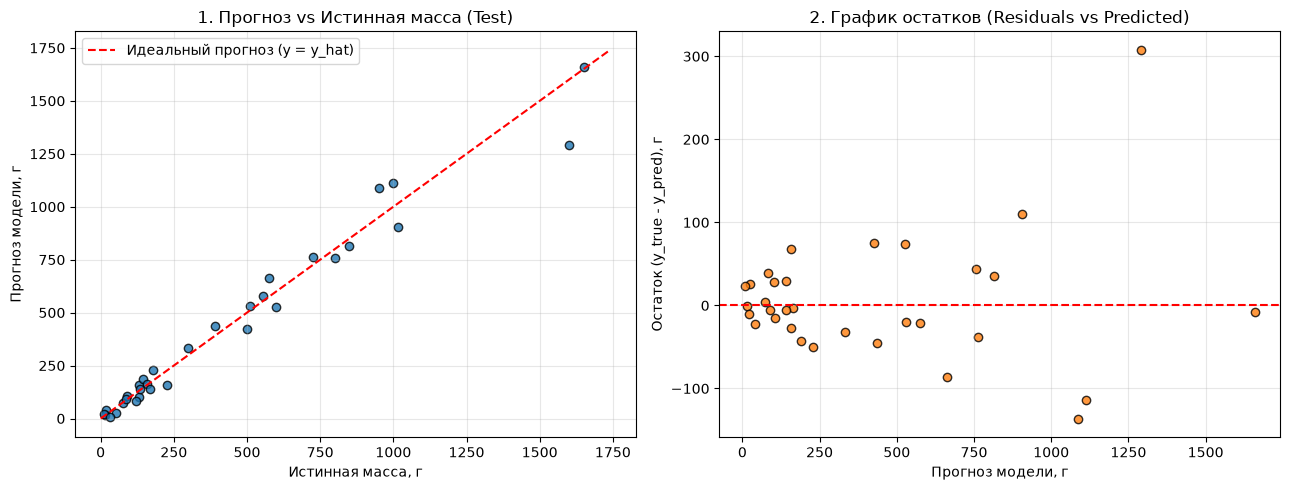

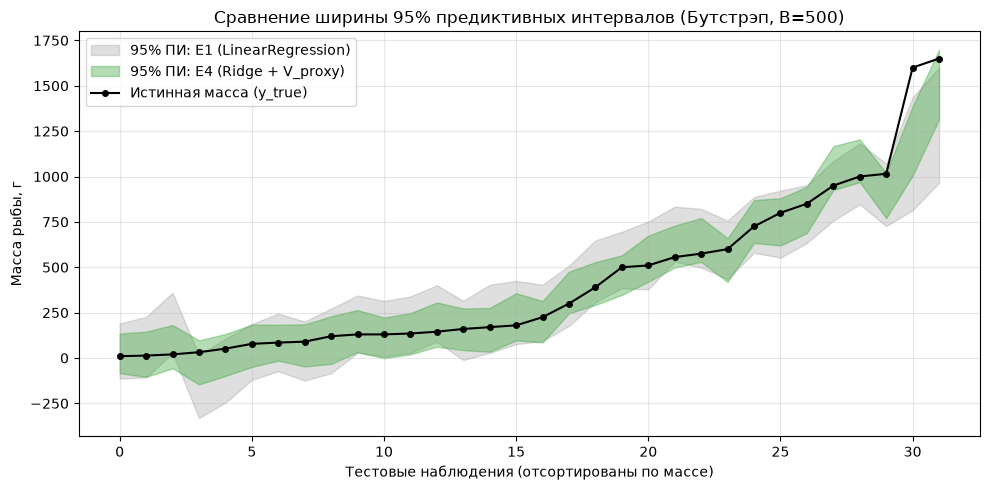

In [1]:
import os
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline

# Безопасный переход в корень проекта
root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.evaluate import get_frozen_split, load_dataset  # type: ignore
from src.features import VolumeAdder  # type: ignore
from src.train import build_preprocessor  # type: ignore
from src.bootstrap import bootstrap_intervals  # type: ignore

os.makedirs("reports/figures", exist_ok=True)

df = load_dataset()
X_train, X_test, y_train, y_test = get_frozen_split(df)
model = joblib.load("models/best_model.joblib")

preds = model.predict(X_test)
residuals = y_test.values - preds

# 1. График: Прогноз vs Истинное значение и Остатки vs Прогноз
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, preds, alpha=0.8, color="#1f77b4", edgecolors="k")
lims = [0, max(y_test.max(), preds.max()) * 1.05]
axes[0].plot(lims, lims, "r--", label="Идеальный прогноз (y = y_hat)")
axes[0].set_title("1. Прогноз vs Истинная масса (Test)")
axes[0].set_xlabel("Истинная масса, г")
axes[0].set_ylabel("Прогноз модели, г")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(preds, residuals, alpha=0.8, color="#ff7f0e", edgecolors="k")
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("2. График остатков (Residuals vs Predicted)")
axes[1].set_xlabel("Прогноз модели, г")
axes[1].set_ylabel("Остаток (y_true - y_pred), г")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("reports/figures/lab02_residuals.png", dpi=150)
plt.show()

# 2. График сравнения 95% предиктивных интервалов E1 vs E4 (бутстрэп)
num_cols = ["Length1", "Length2", "Length3", "Height", "Width"]
cat_cols = ["Species"]

pipe_e1 = Pipeline([("preprocess", build_preprocessor(num_cols, cat_cols)), ("regressor", LinearRegression())])
pipe_e4 = Pipeline([("add_volume", VolumeAdder()), ("preprocess", build_preprocessor(num_cols + ["V_proxy"], cat_cols)), ("regressor", Ridge(alpha=1.0))])

res_e1 = bootstrap_intervals(pipe_e1, X_train, y_train, X_test)
res_e4 = bootstrap_intervals(pipe_e4, X_train, y_train, X_test)

order = np.argsort(y_test.values)
y_sorted = y_test.values[order]

plt.figure(figsize=(10, 5))
plt.fill_between(range(len(y_sorted)), res_e1["pi_low"].values[order], res_e1["pi_high"].values[order],
                 color="gray", alpha=0.25, label="95% ПИ: E1 (LinearRegression)")
plt.fill_between(range(len(y_sorted)), res_e4["pi_low"].values[order], res_e4["pi_high"].values[order],
                 color="#2ca02c", alpha=0.35, label="95% ПИ: E4 (Ridge + V_proxy)")
plt.plot(range(len(y_sorted)), y_sorted, "ko-", markersize=4, label="Истинная масса (y_true)")
plt.title("Сравнение ширины 95% предиктивных интервалов (Бутстрэп, B=500)")
plt.xlabel("Тестовые наблюдения (отсортированы по массе)")
plt.ylabel("Масса рыбы, г")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("reports/figures/lab02_bootstrap_ci.png", dpi=150)
plt.show()